# Drone Weight — Exploratory Data Analysis

This notebook characterises the drone weight data used by the optimization component.

**Dataset:** FPV-DB open component catalogue (CC BY 4.0, doi:10.5281/zenodo.23613812).
**Target:** all-up weight (AUW) of 101 assembled quadrotors, reconstructed as
`dry mass + catalogue-matched battery mass`.

The PEMFC dataset in this repository was audited first and contains **no mass, thrust,
payload or battery variables**, so it cannot support this component (see
`outputs/data_audit.json` and the project's own `Notes` sheet).

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd, numpy as np
pd.set_option("display.width", 200)
from src.config import DATA_PROCESSED, OUTPUTS, FIGURES
from src.eda import run_eda, descriptives, vif_table

quad = pd.read_csv(DATA_PROCESSED / "quad_design_table.csv")
print("quad design table:", quad.shape)
quad[["brand","model","class_group","prop_size_in","wheelbase_mm",
      "dry_mass_g","battery_mass_g","auw_est_g"]].head(10)

quad design table: (101, 34)


,brand,model,class_group,prop_size_in,wheelbase_mm,dry_mass_g,battery_mass_g,auw_est_g
0,Axisflying,KOLAS 6,long range,6.0,245.0,385.00,230.00,615.00
1,Axisflying,Manta 3.5,freestyle,3.5,162.0,233.00,151.00,384.00
2,Axisflying,Manta 5 SE,freestyle,5.1,223.0,461.10,230.00,691.10
3,BetaFPV,Air65,tiny whoop,1.2,65.0,17.30,8.28,25.58
4,BetaFPV,Air75,tiny whoop,1.6,75.0,21.00,12.70,33.70
5,BetaFPV,Aquila16,whoop,1.8,86.0,47.10,25.50,72.60
6,BetaFPV,Beta95X V3,cinewhoop,2.5,95.0,99.10,62.00,161.10
7,BetaFPV,Cetus Pro,whoop,1.6,NaN,33.19,12.70,45.89
8,BetaFPV,Cetus X,whoop,2.0,95.0,56.00,27.00,83.00
9,BetaFPV,HX115 LR,toothpick,3.0,126.0,44.00,12.70,56.70


## 1. Missingness and duplicates

In [2]:
miss = quad.isna().mean().sort_values(ascending=False)
print("duplicate brand/model rows:", int(quad.duplicated(subset=["brand","model"]).sum()))
print(miss[miss > 0].round(3).to_string())

duplicate brand/model rows: 0
auw_reported_g                  0.683
manufacturer_flight_time_min    0.535
flight_controller               0.465
log_wheelbase                   0.257
wheelbase_mm                    0.257
motor_kv                        0.099
motors                          0.020
typical_current_a               0.010
power_to_weight_W_kg            0.010
power_W                         0.010


Missingness is **informative**, not random: 69 of 101 aircraft have no published AUW
and 26 have no wheelbase. These are omitted specifications. Wheelbase is median-imputed
with a `wheelbase_missing` indicator in the model; the published AUW is used only as an
external validation target.

## 2. Descriptive statistics

In [3]:
desc = descriptives(quad)
desc[["variable","n","missing","mean","sd","min","median","max","cv_pct","skew",
      "iqr_outliers","robust_outliers_3.5"]].round(2)

,variable,n,missing,mean,sd,min,median,max,cv_pct,skew,iqr_outliers,robust_outliers_3.5
0,prop_size_in,101,0,3.08,1.45,1.20,2.50,7.50,47.09,0.85,1,1
1,wheelbase_mm,75,26,142.79,66.88,65.00,123.00,336.00,46.84,0.93,2,0
2,cells,101,0,3.54,1.86,1.00,4.00,6.00,52.71,-0.00,0,0
3,capacity_mah,101,0,1081.14,1177.06,300.00,850.00,8000.00,108.87,4.45,6,5
4,motor_kv,91,10,8089.12,7202.03,1250.00,4600.00,28000.00,89.03,1.07,0,9
5,battery_mass_g,101,0,131.62,183.12,8.00,95.00,1175.00,139.13,4.11,3,3
6,dry_mass_g,101,0,190.86,202.06,17.30,141.00,1466.00,105.87,3.03,3,3
7,auw_est_g,101,0,322.48,367.41,25.58,245.40,2211.00,113.93,2.98,3,3
8,energy_wh,101,0,17.75,26.99,1.11,11.10,177.60,152.05,4.48,3,3
9,disk_loading_kg_m2,101,0,13.61,6.67,3.07,12.04,31.82,48.99,1.02,2,2


AUW spans **25.6–2,211 g** with a median of 245 g and a coefficient of variation of 114 %.
The three IQR outliers are genuine 6–7 inch cinelifters and are retained: they define the
upper end of the design envelope used by the optimizer. Deleting them would shrink the
feasible design space.

## 3. Correlation and multicollinearity

In [4]:
cols = ["auw_est_g","dry_mass_g","battery_mass_g","energy_wh","wheelbase_mm",
        "prop_size_in","cells","capacity_mah","motor_kv","disk_loading_kg_m2"]
corr = quad[cols].corr()
corr["auw_est_g"].drop("auw_est_g").sort_values(ascending=False).round(3)

dry_mass_g            0.958
battery_mass_g        0.949
energy_wh             0.916
wheelbase_mm          0.861
capacity_mah          0.857
prop_size_in          0.825
cells                 0.716
disk_loading_kg_m2    0.371
motor_kv             -0.587
Name: auw_est_g, dtype: float64

In [5]:
from src.eda import vif_table
vif_table(quad[["prop_size_in","wheelbase_mm","cells","capacity_mah","motor_kv"]])

,feature,VIF
0,prop_size_in,8.21
1,cells,6.54
2,wheelbase_mm,4.81
3,motor_kv,3.40
4,capacity_mah,1.93


Prop size, cell count and wheelbase are collinear (VIF 4.8–8.2) because they all encode
vehicle size. Tree models tolerate this; linear models require regularisation, which is
why Ridge and Lasso are kept in the benchmark.

Motor KV is **negatively** correlated with weight (r = −0.59): small high-KV motors belong
to micro quads, large low-KV motors to heavy lifters. KV is a class marker, not a mass driver.

## 4. Allometric scaling

In [6]:
from src.eda import allometric_fit
fits = [allometric_fit(quad, "wheelbase_mm"), allometric_fit(quad, "prop_size_in"),
        allometric_fit(quad, "wheelbase_mm", "dry_mass_g"),
        allometric_fit(quad, "prop_size_in", "dry_mass_g")]
pd.DataFrame(fits)[["x","y","n","exponent","exponent_se","r2","p_value"]].round(4)

,x,y,n,exponent,exponent_se,r2,p_value
0,wheelbase_mm,auw_est_g,75,2.2865,0.1238,0.8237,0.0
1,prop_size_in,auw_est_g,101,2.1158,0.1042,0.8063,0.0
2,wheelbase_mm,dry_mass_g,75,2.1452,0.1206,0.8126,0.0
3,prop_size_in,dry_mass_g,101,1.9739,0.1028,0.7882,0.0


The exponents are close to 2 (2.12–2.29), i.e. mass grows roughly with the square of
linear size rather than with volume. This is the empirical justification for treating
frame/prop size as a first-order weight lever, and for constraining the optimizer to the
observed size envelope instead of extrapolating.

## 5. Component-level relationships

In [7]:
cat = pd.read_csv(DATA_PROCESSED / "component_catalog.csv")
print("components:", cat.shape[0])
cat.groupby("component_type")["weight_g"].agg(["count","median","min","max"]).round(2)

components: 1037


,count,median,min,max
component_type,,,,
batterie,326,100.0,6.10,1990.0
camera,47,7.5,1.10,17.6
motor,199,30.4,1.40,148.1
prop,195,4.1,0.16,118.0
quad,101,141.0,17.30,1466.0
stack,53,8.5,2.00,59.0
vtx,116,13.0,0.60,110.0


In [8]:
batt = pd.read_csv(DATA_PROCESSED / "battery_catalog.csv")
a, b = np.polyfit(batt["energy_wh"], batt["weight_g"], 1)
r2 = np.corrcoef(batt["energy_wh"], batt["weight_g"])[0,1]**2
print(f"m_batt = {a:.3f} g/Wh x E + {b:.2f} g   (R2 = {r2:.3f}, n = {len(batt)})")
print(f"median pack specific energy = {(batt.energy_wh/batt.weight_g*1000).median():.0f} Wh/kg")

m_batt = 5.678 g/Wh x E + 25.20 g   (R2 = 0.972, n = 326)
median pack specific energy = 138 Wh/kg


Battery mass is almost perfectly linear in stored energy (R² = 0.972). This is the
mechanism that makes **endurance and weight compete directly**: every extra minute of
endurance requires energy, and energy costs mass at a nearly constant rate.

## 6. Figures

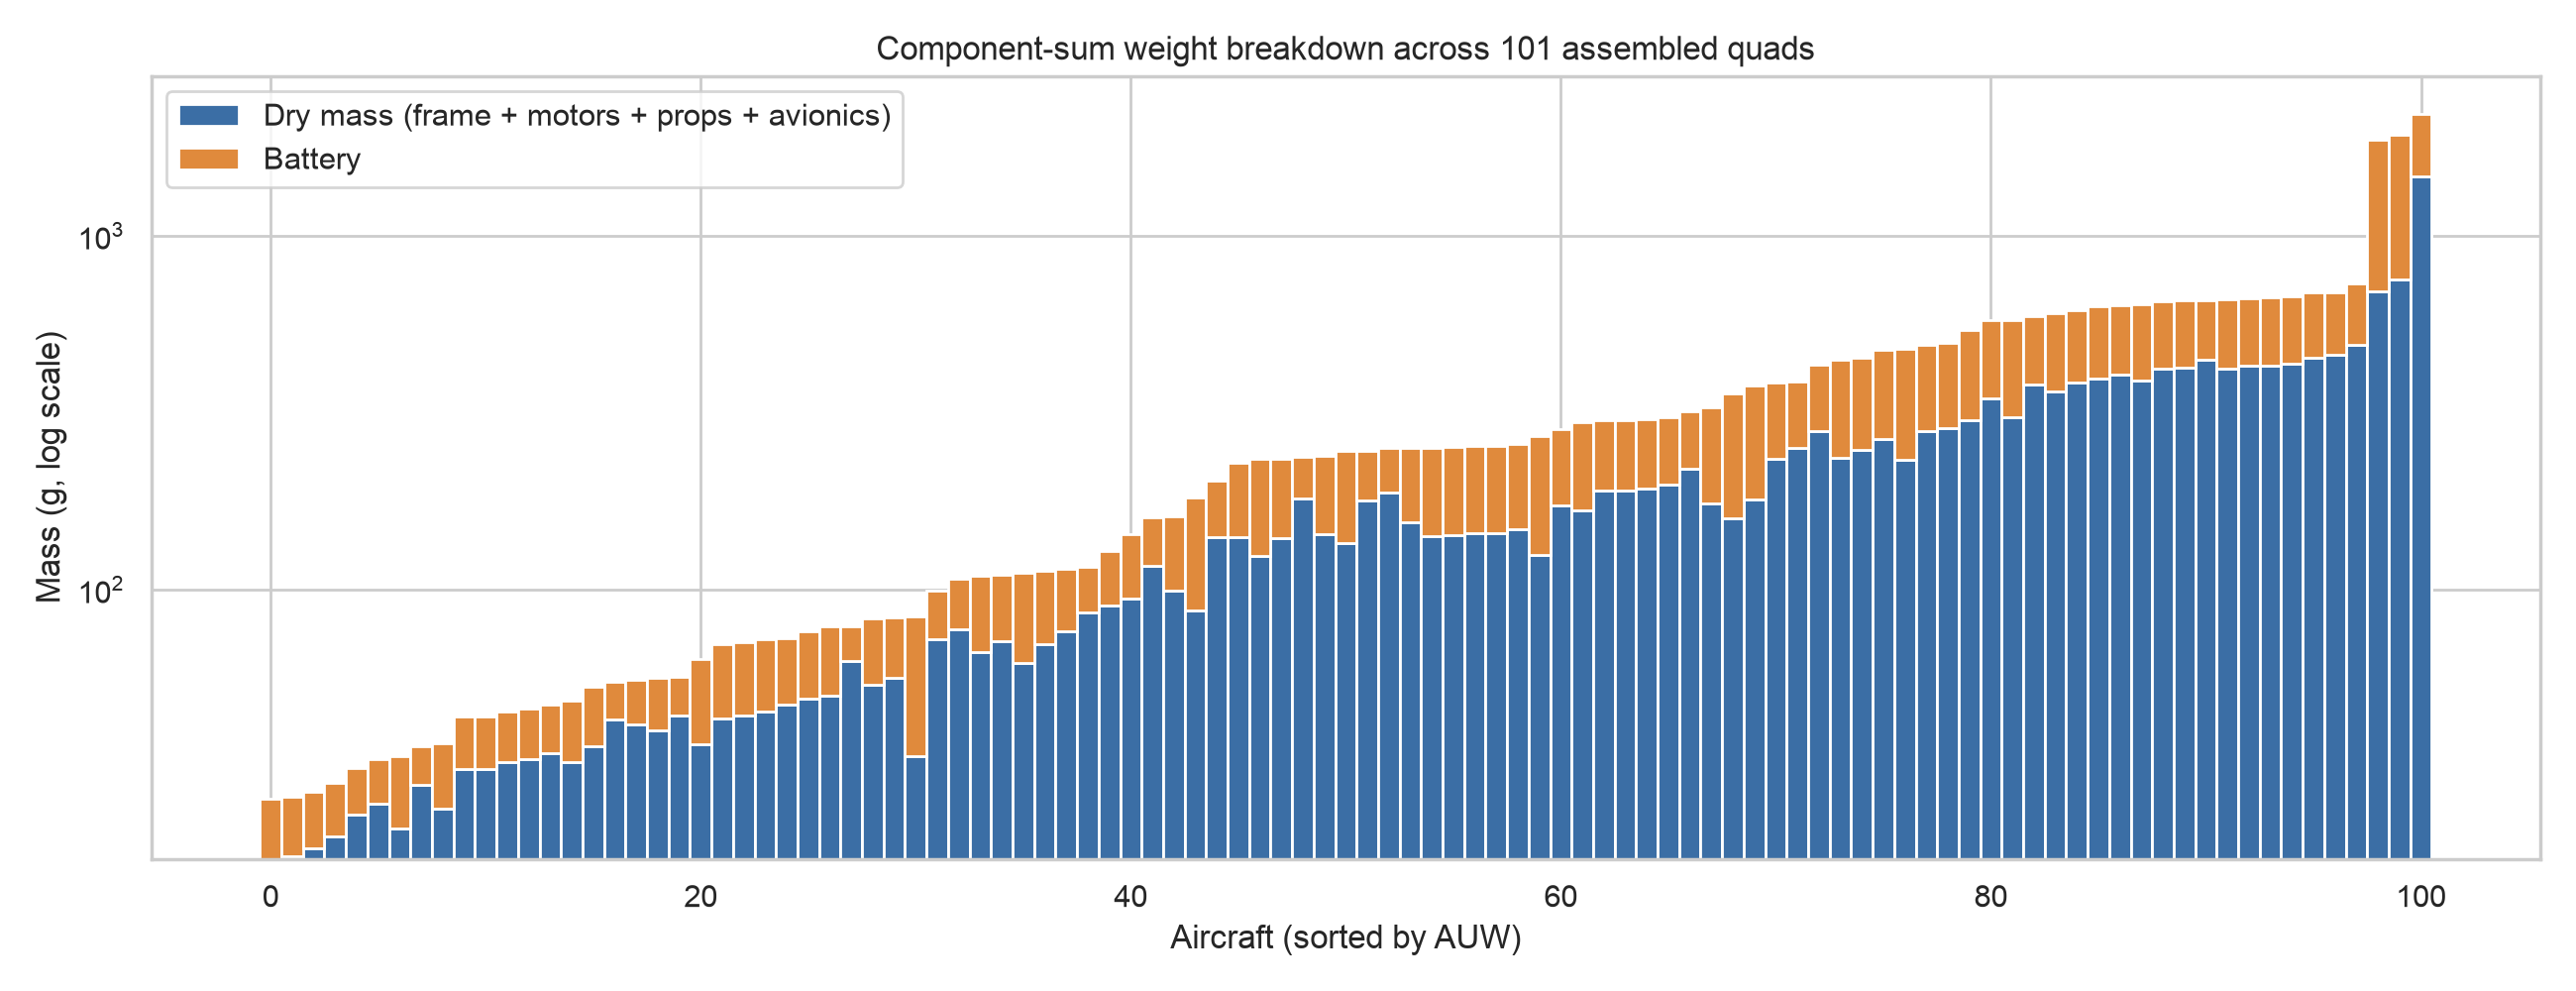

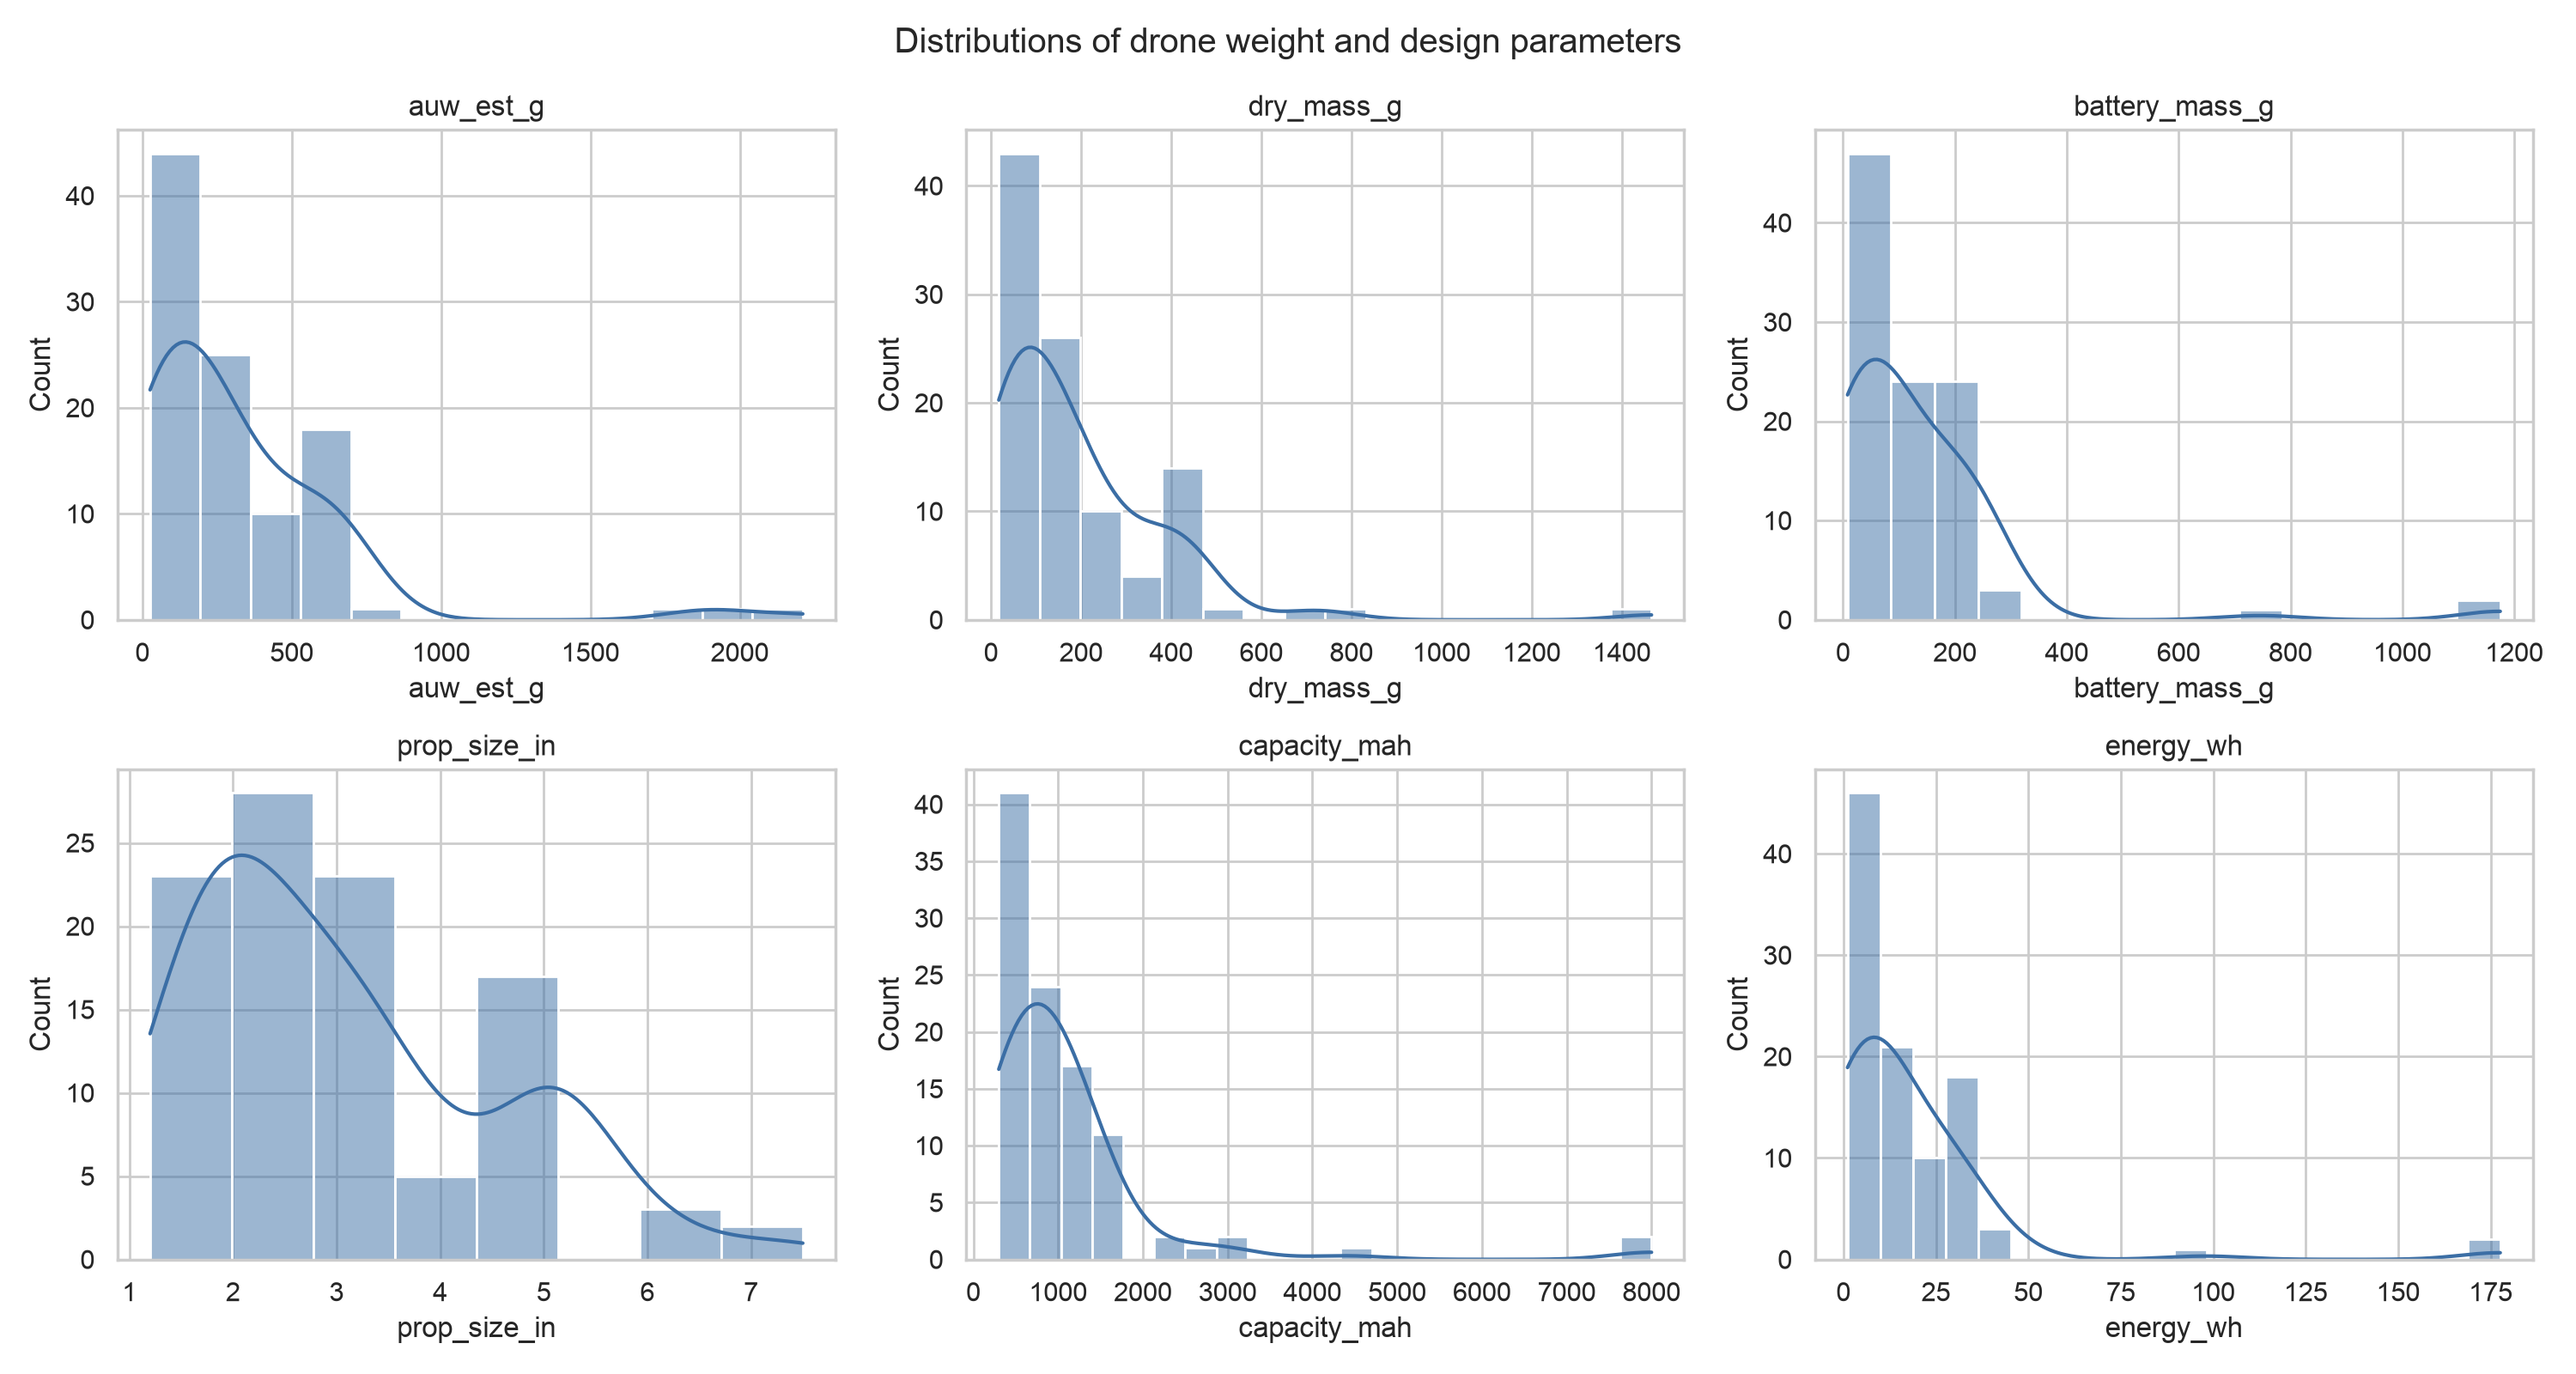

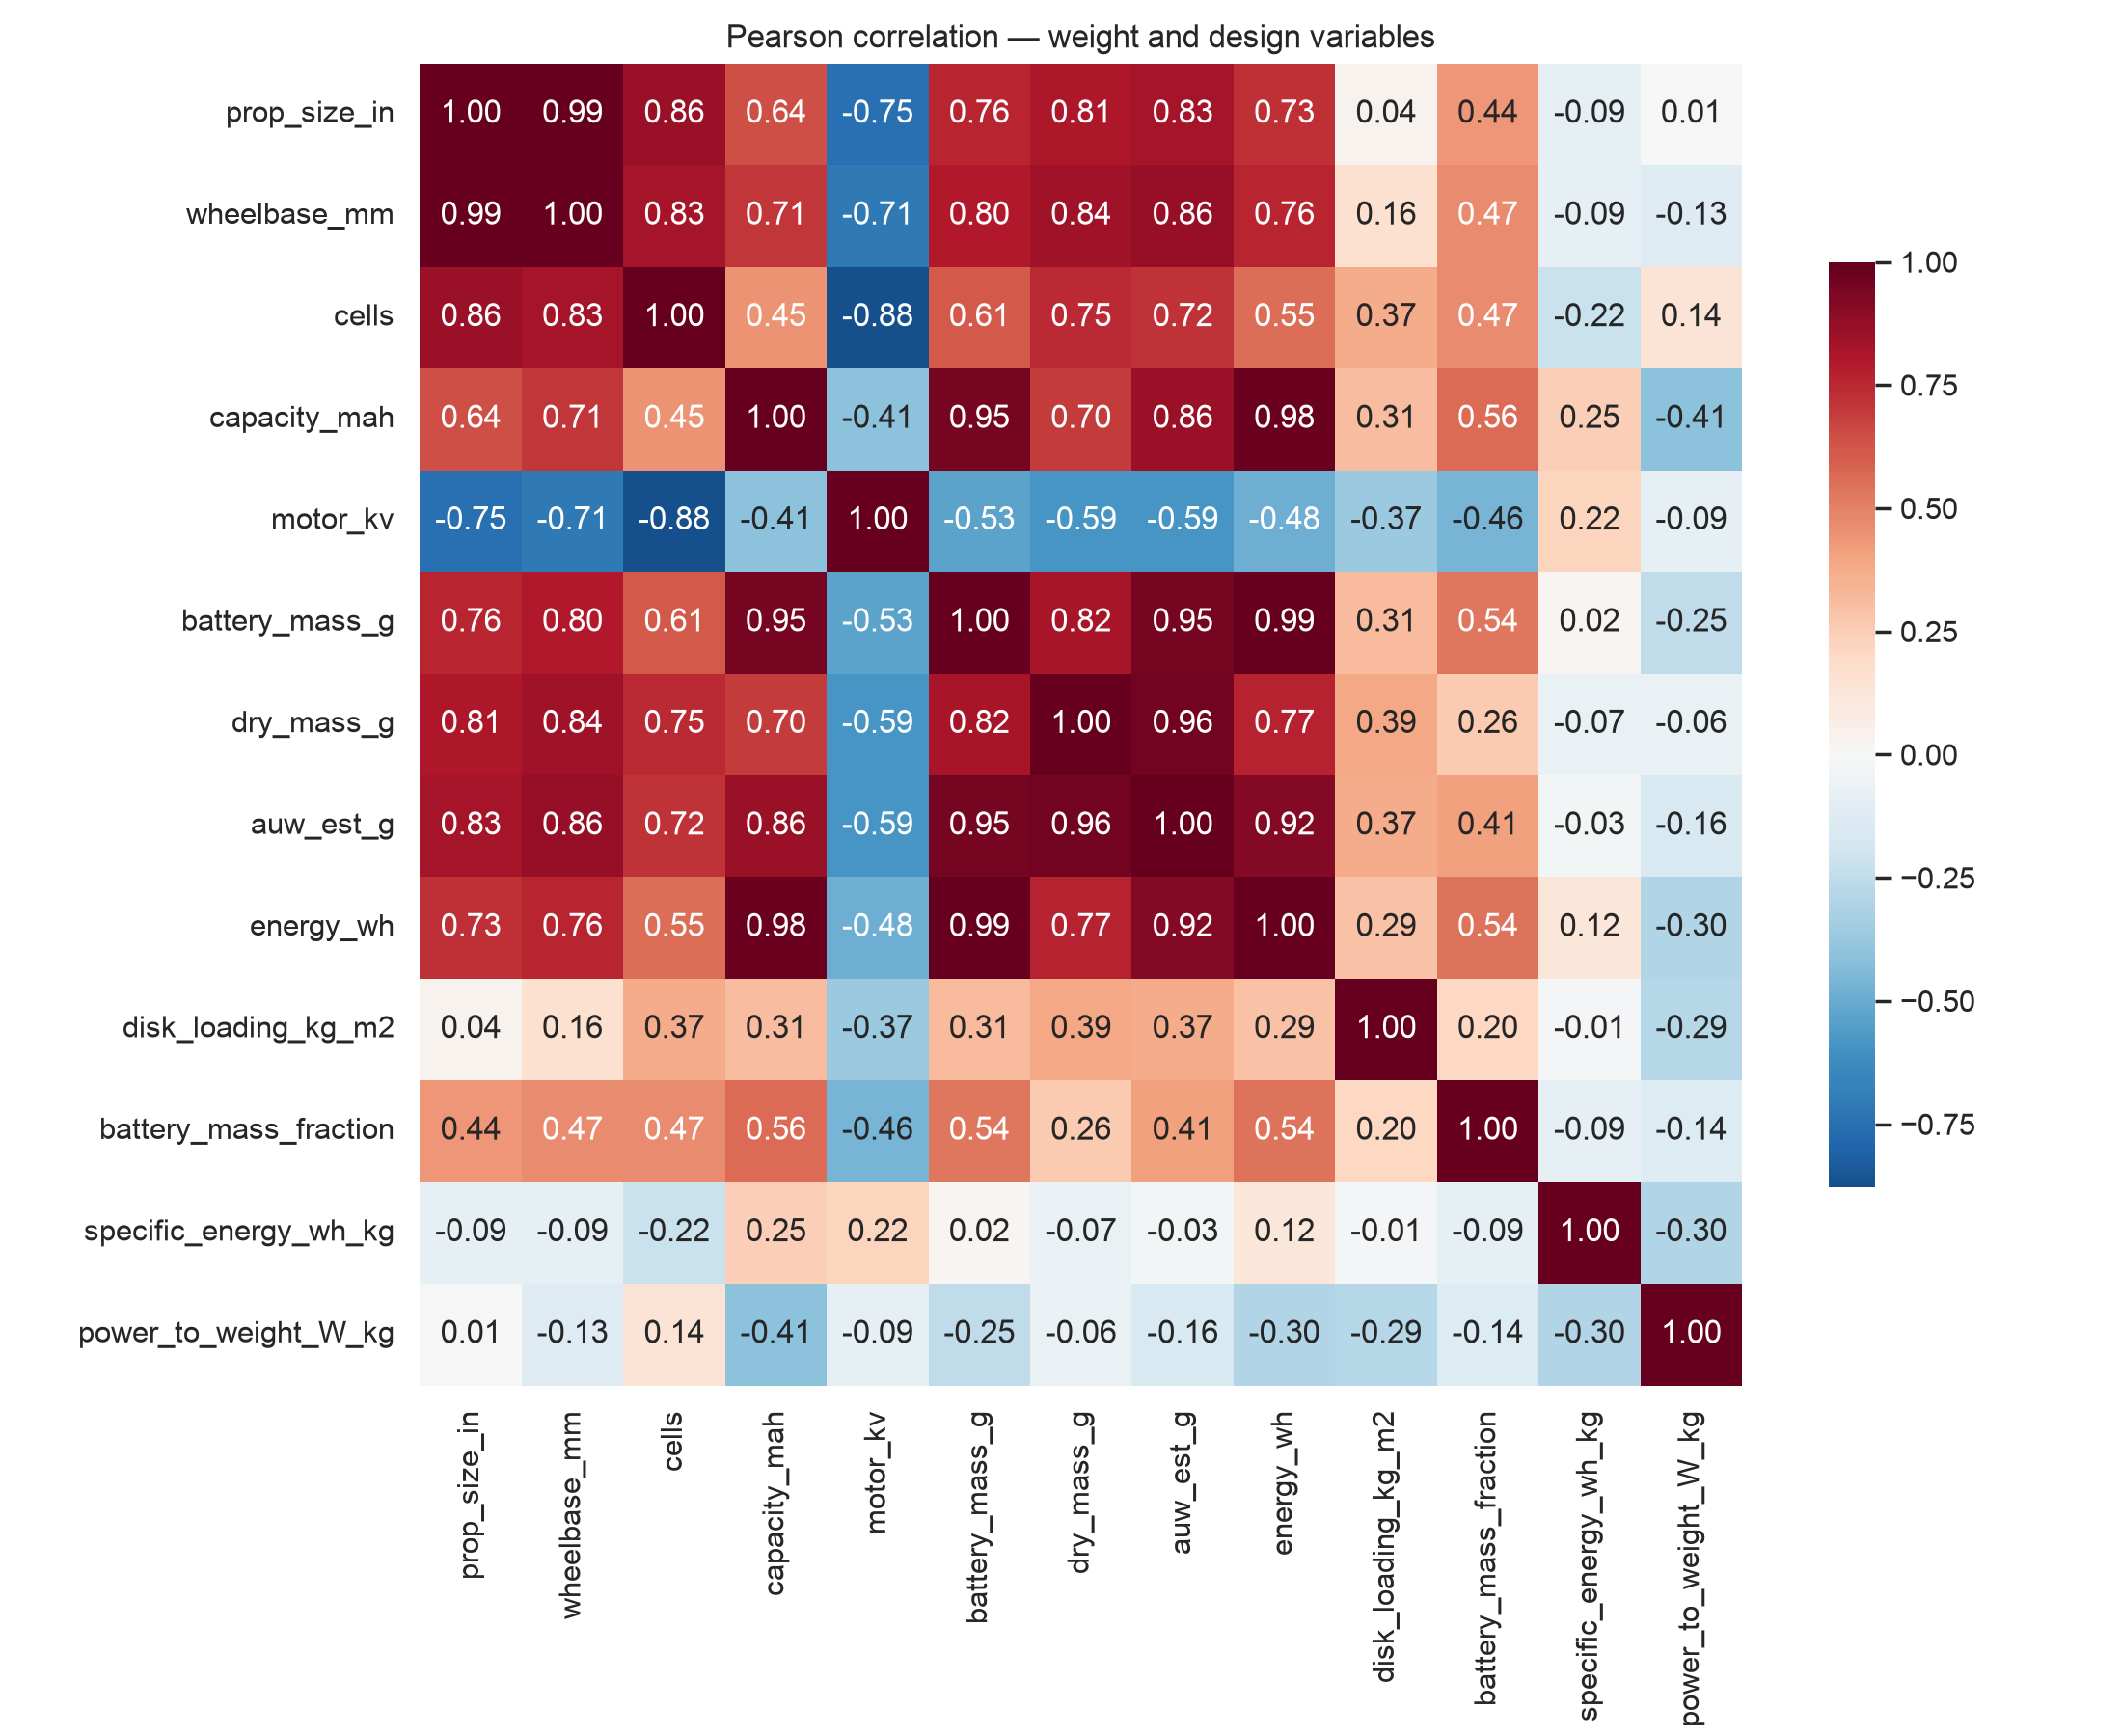

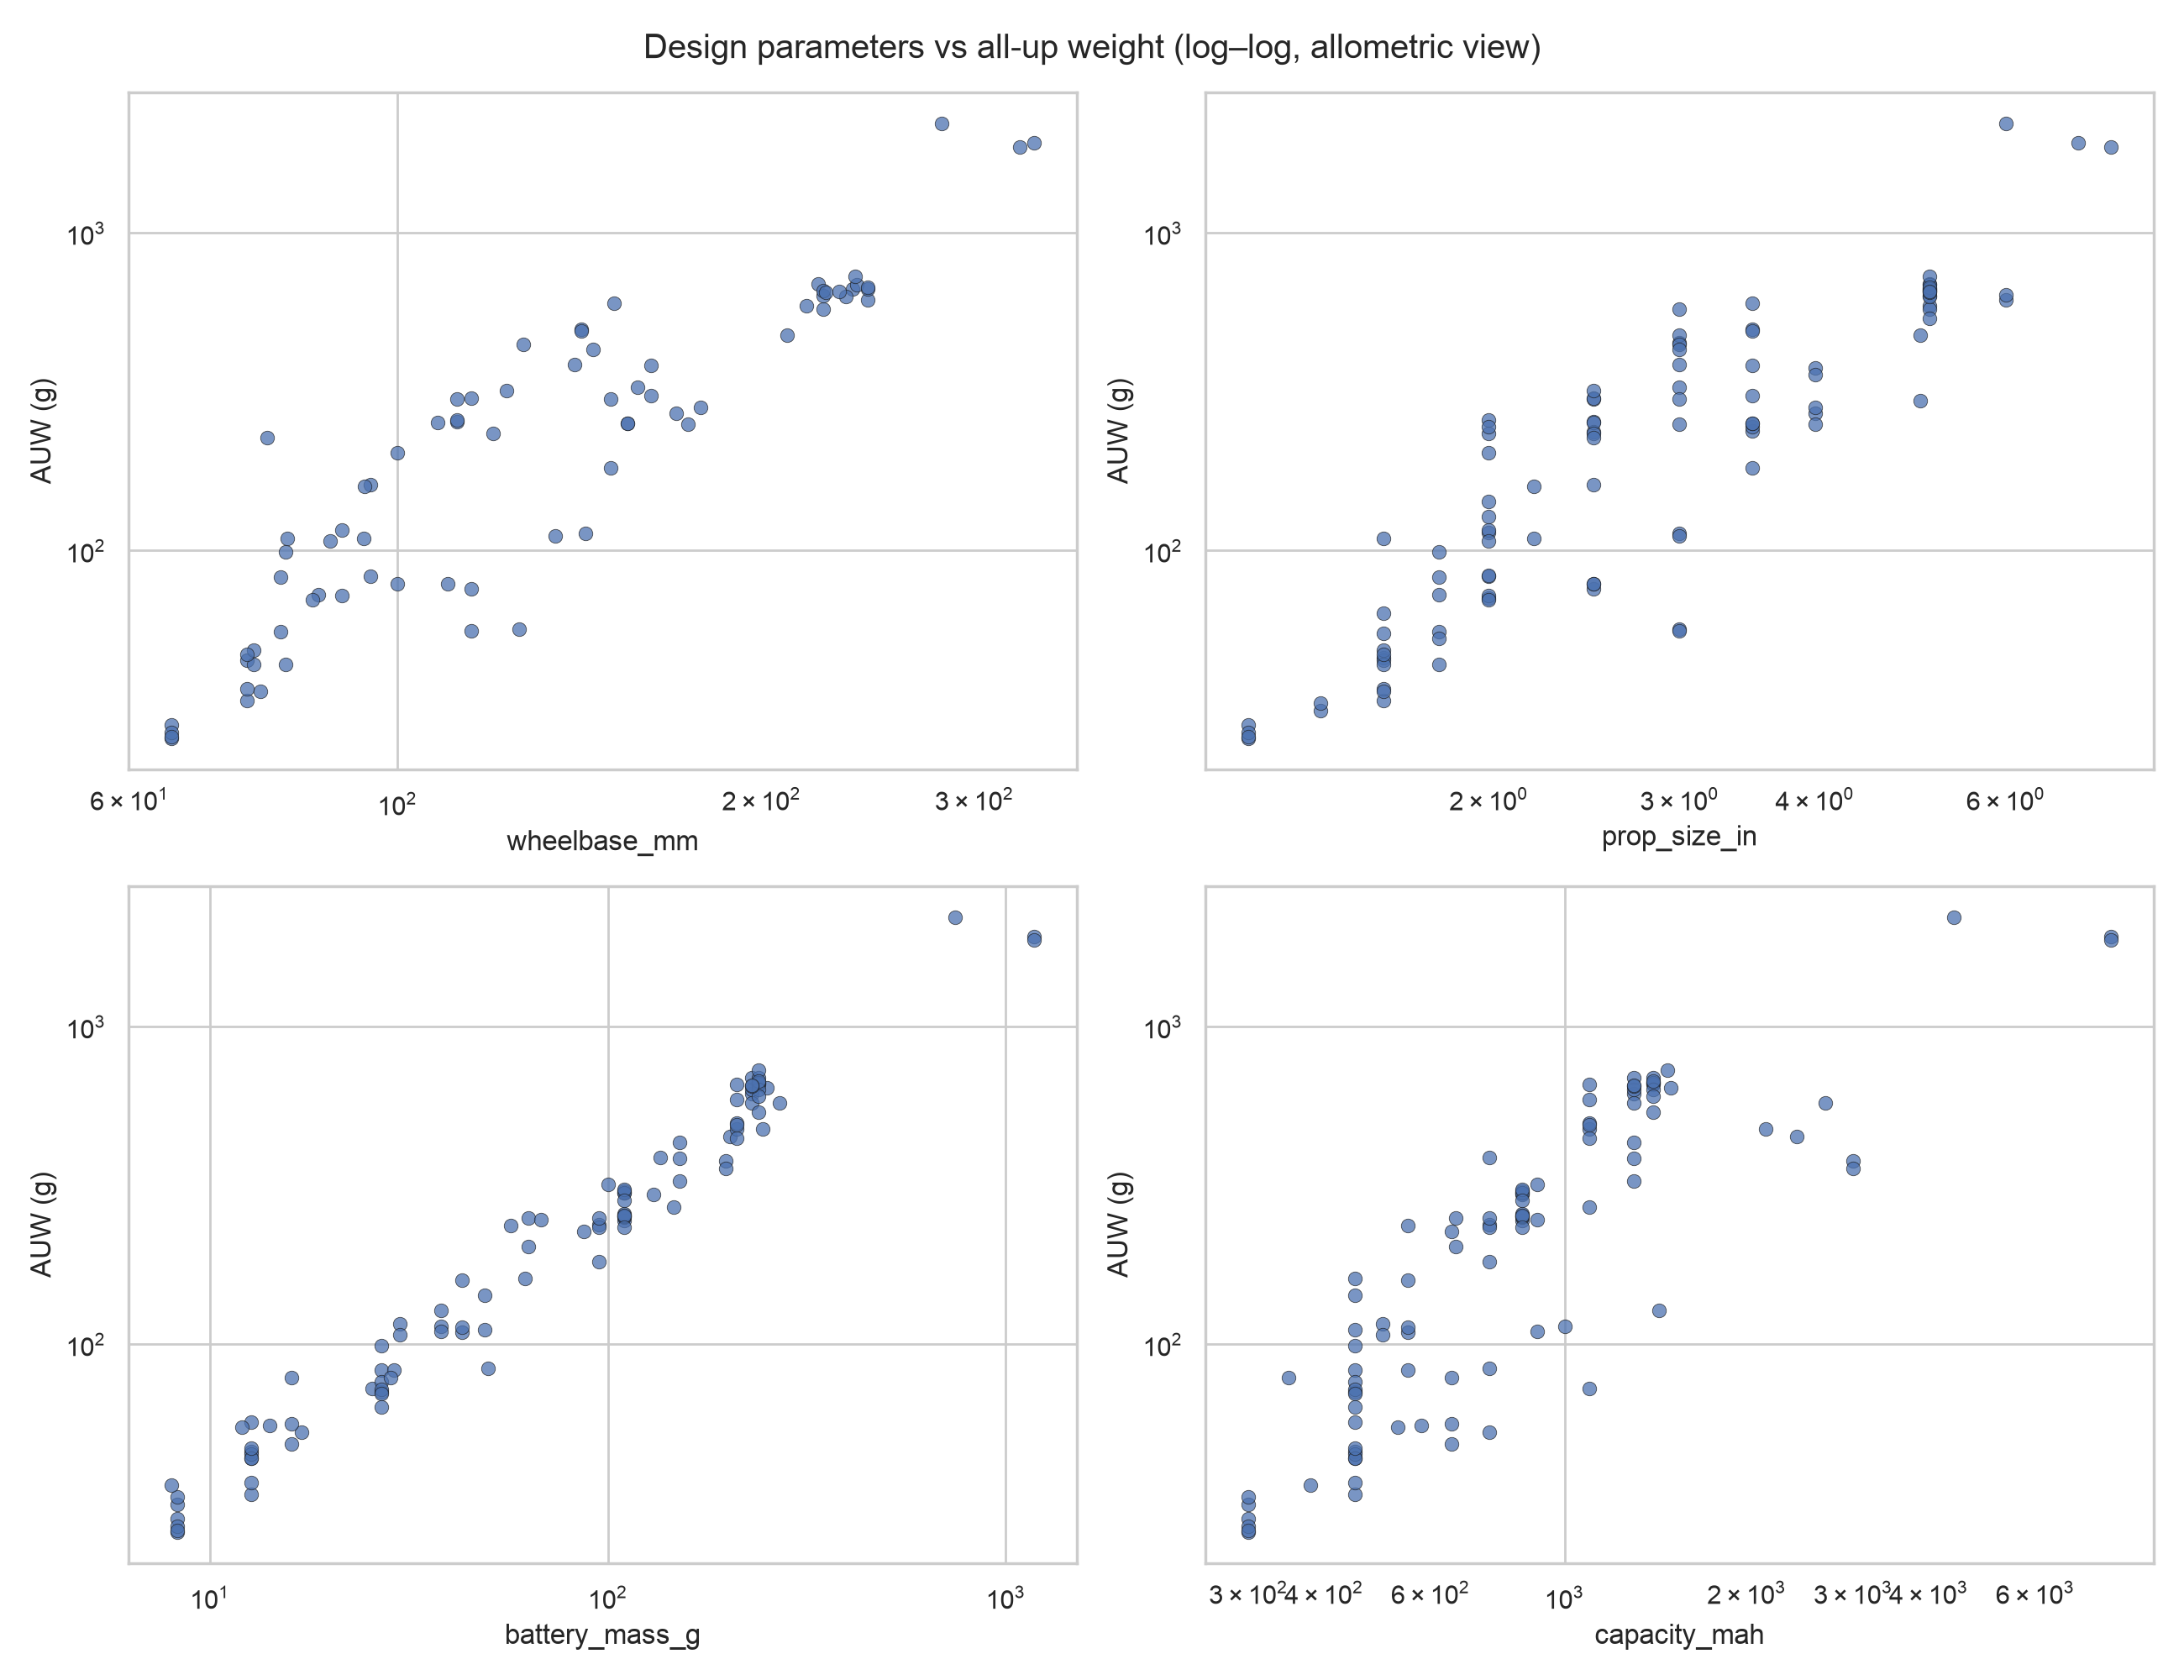

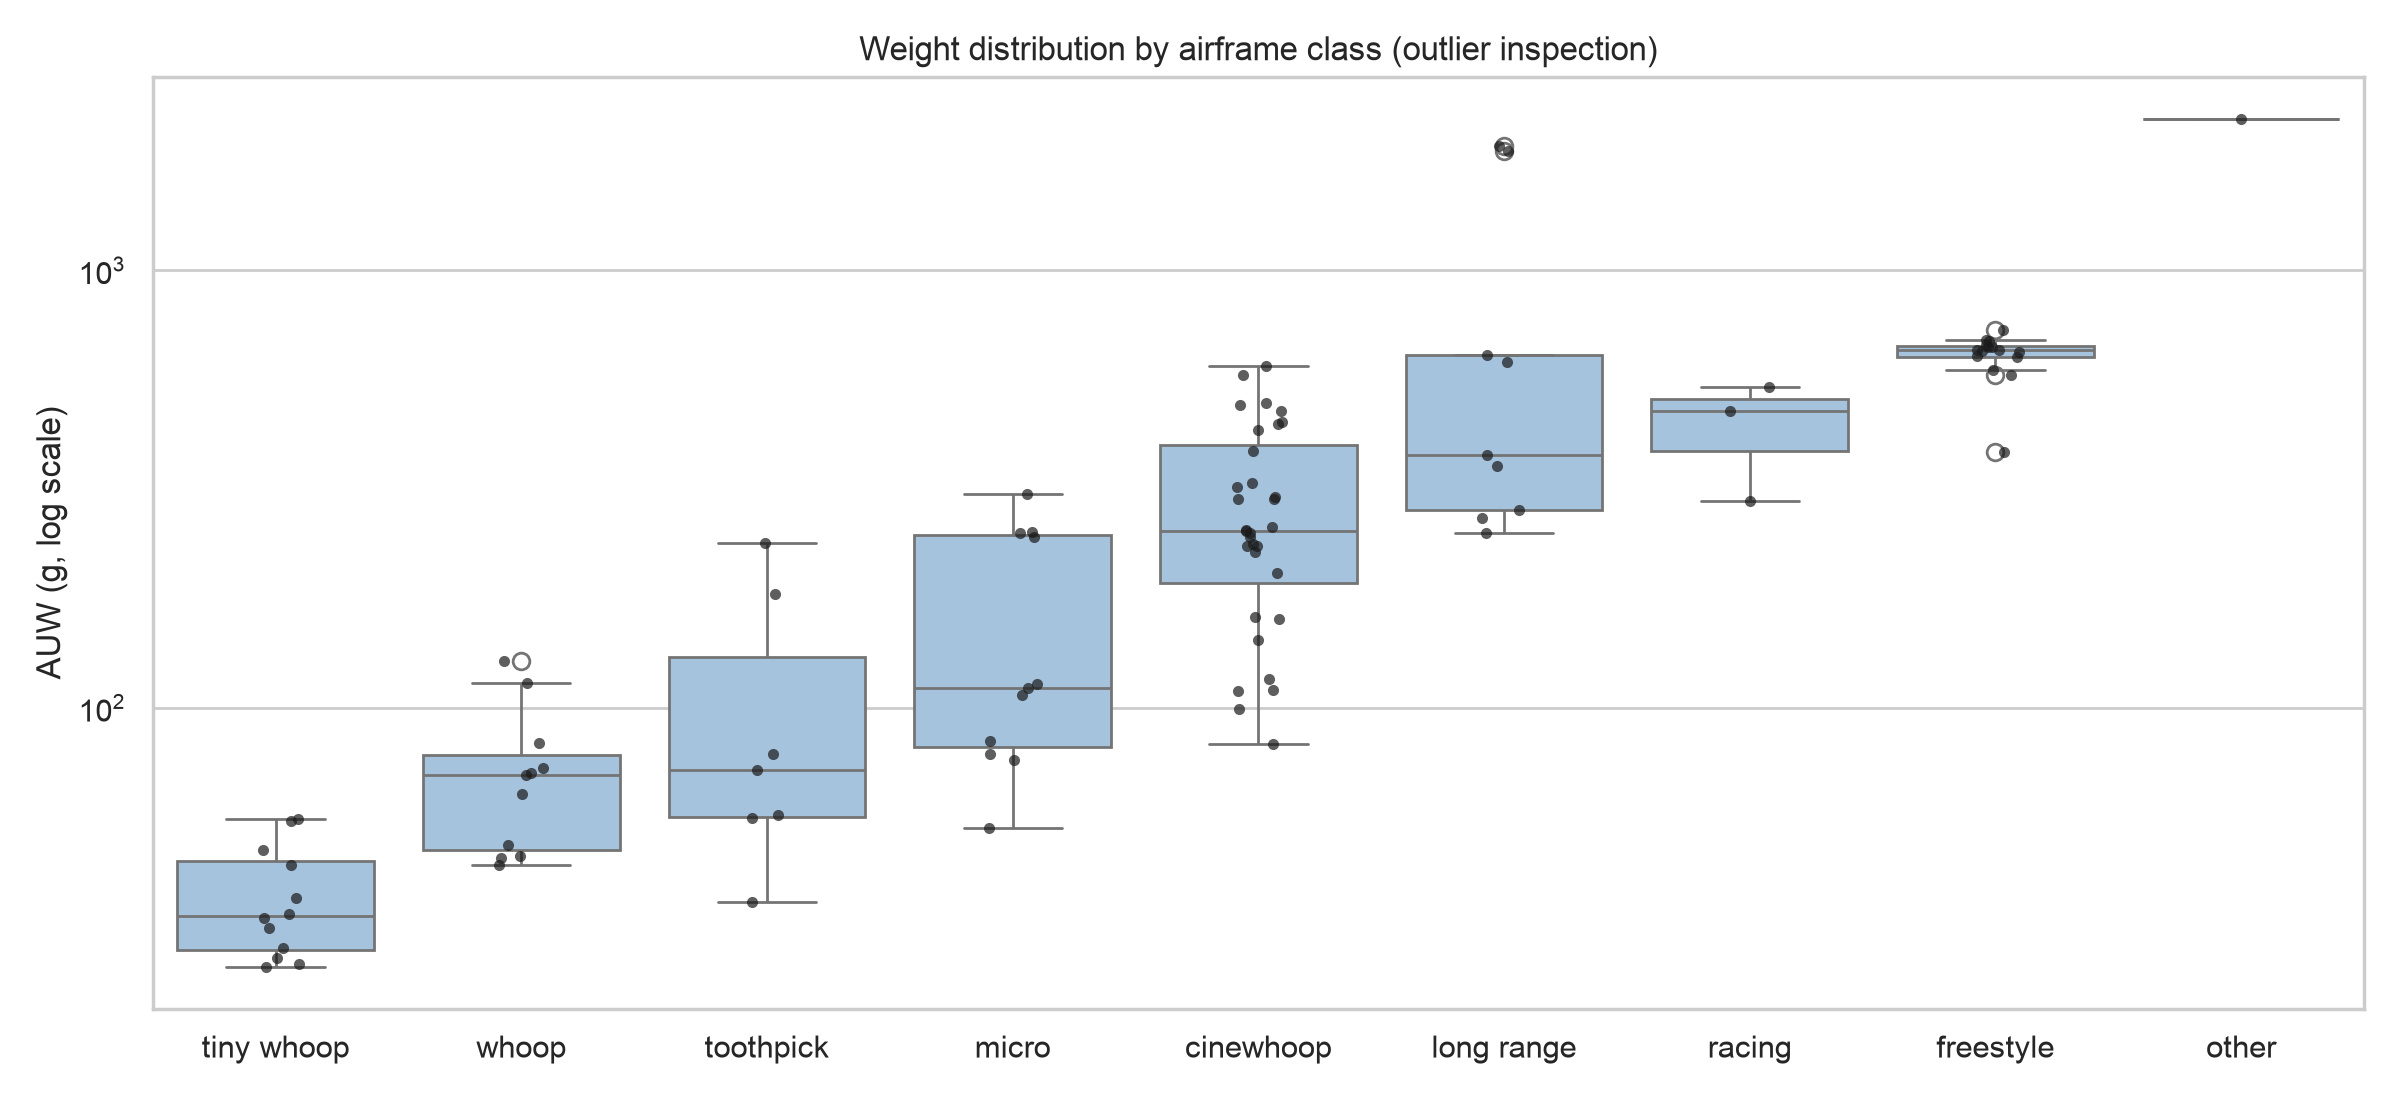

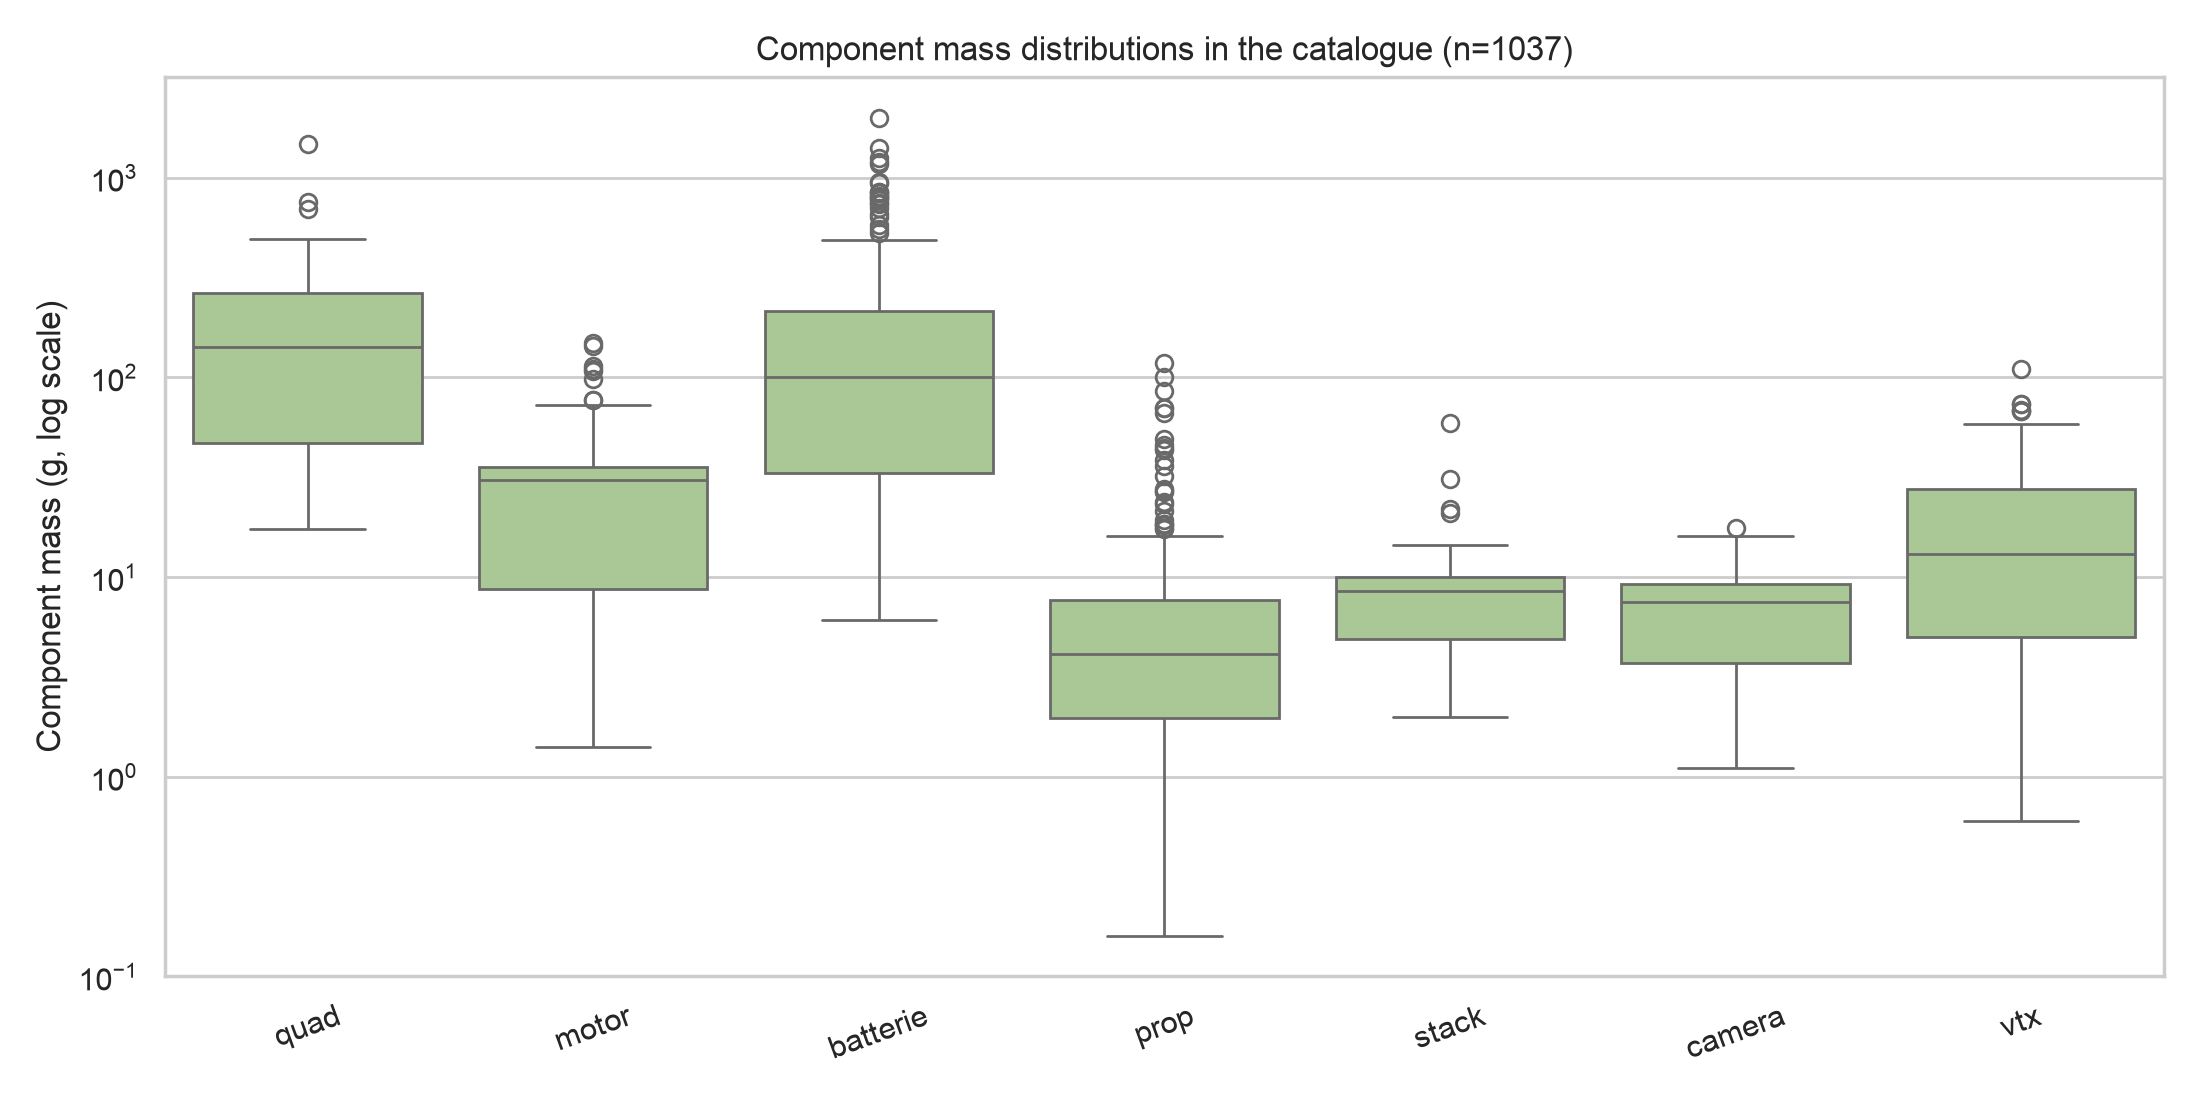

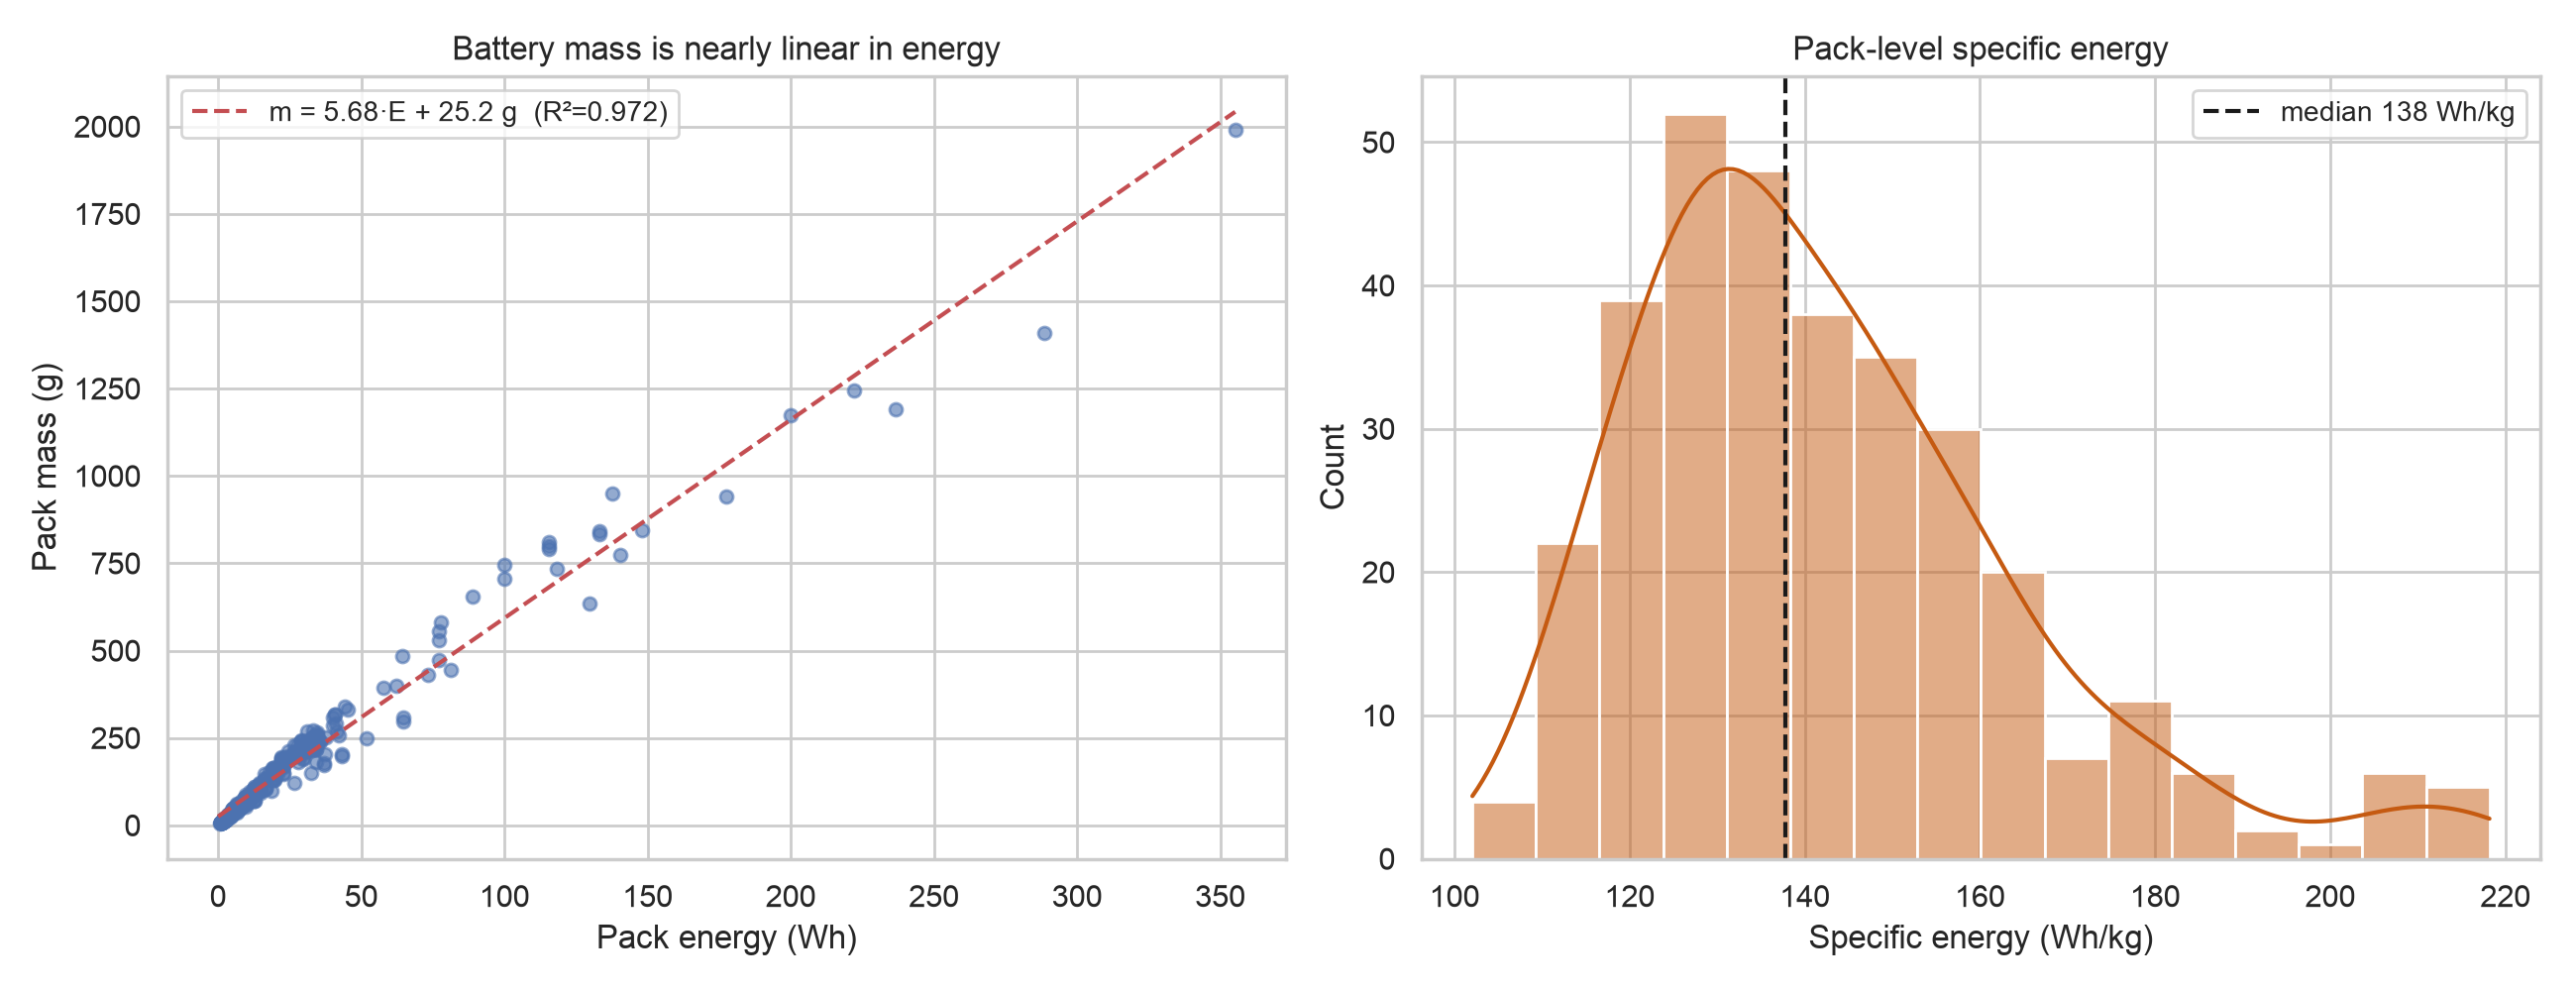

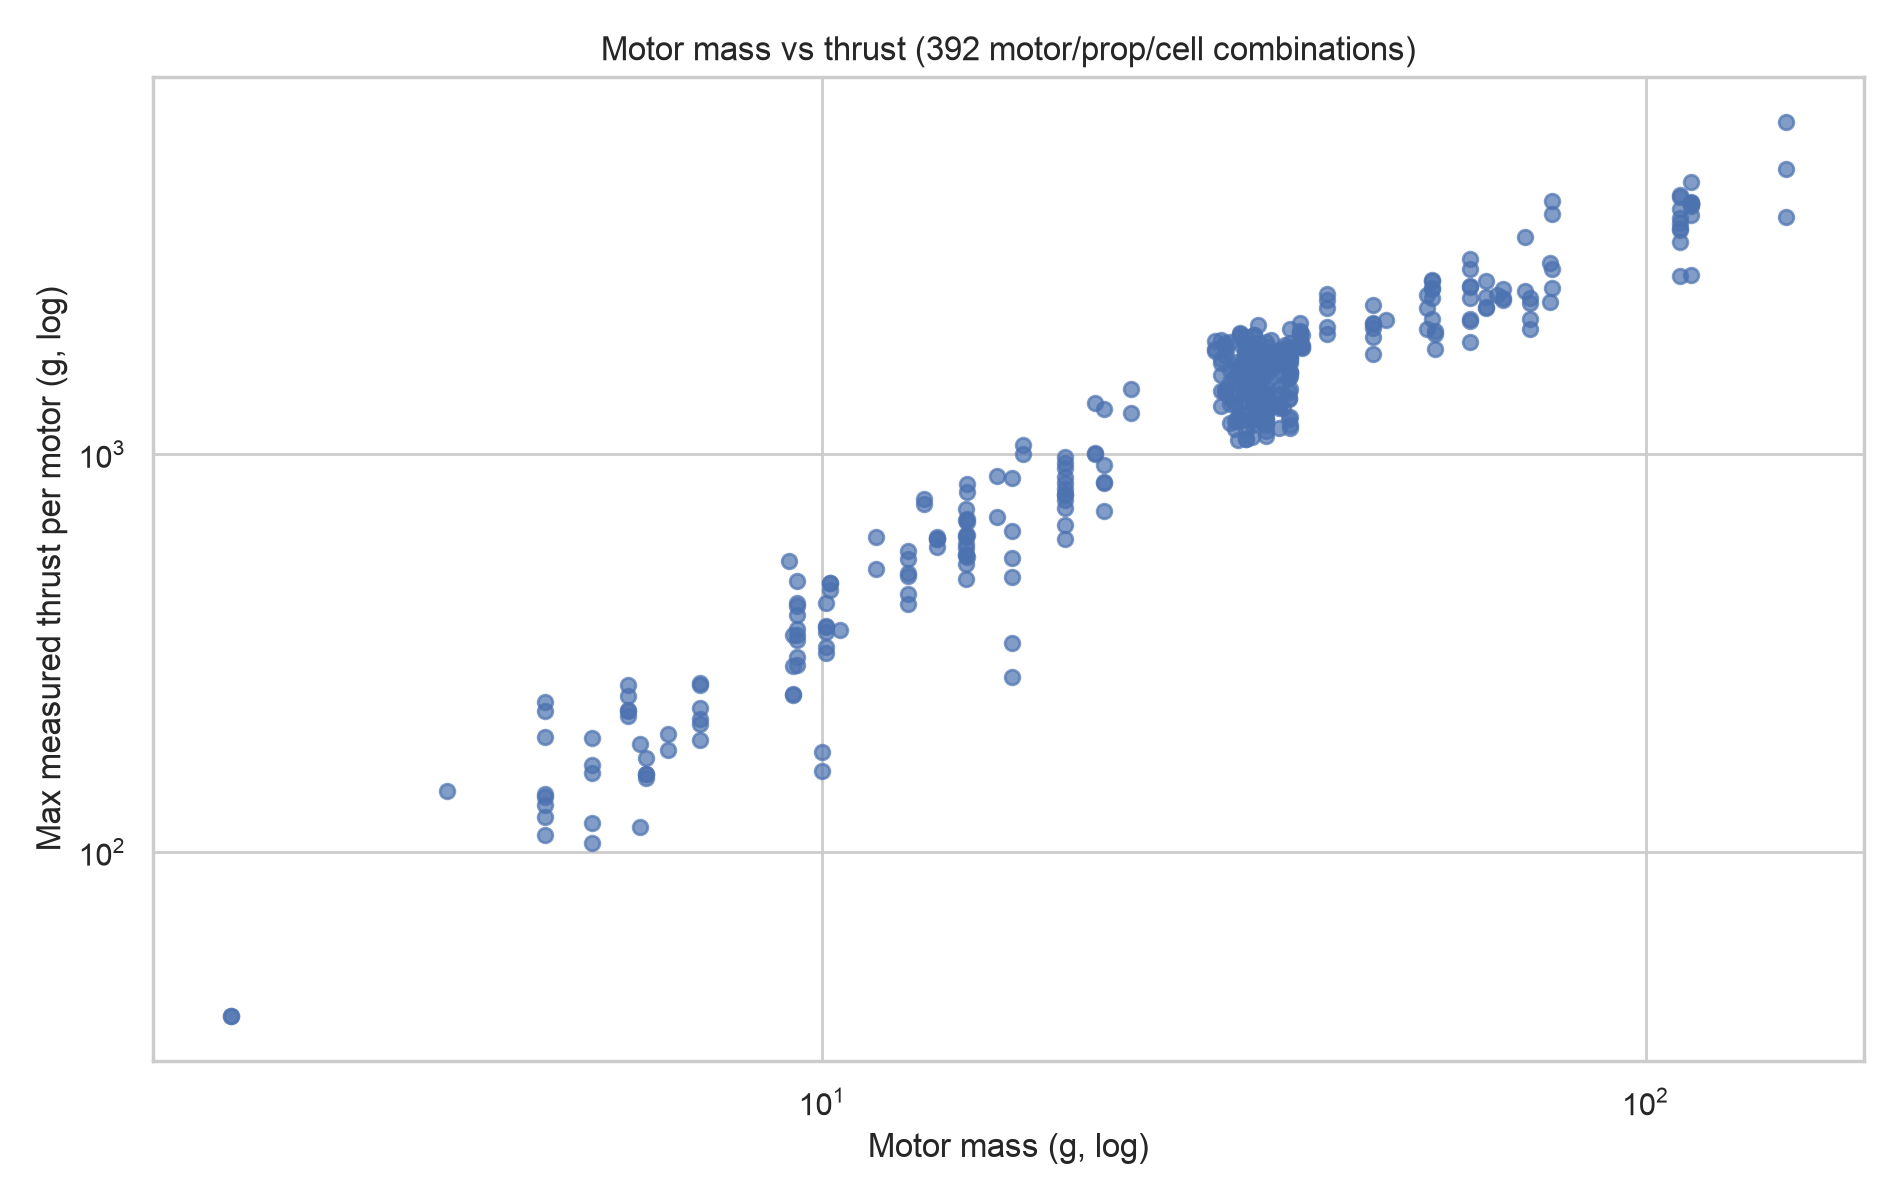

In [9]:
from IPython.display import Image, display
for name in ["component_weight_breakdown","distributions","correlation_heatmap",
             "design_vs_weight","weight_outliers_by_class","component_mass_by_type",
             "battery_energy_mass","motor_mass_vs_thrust"]:
    display(Image(filename=str(FIGURES / f"{name}.png"), width=820))

**What the figures show**

* *Component breakdown* — dry mass and battery mass grow together across two orders of
  magnitude; battery share is roughly constant (median 36 %).
* *Distributions* — all mass variables are strongly right-skewed; log transforms are the
  appropriate scale.
* *Correlation heatmap* — size and energy dominate; temperature-like or KV variables do not.
* *Design vs weight* — log–log slopes near 2 confirm area-like scaling.
* *Outliers by class* — the heavy tail is a class effect, not measurement error.
* *Component masses by type* — batteries and stacks span the widest mass range, motors
  and props are tightly clustered; this is why battery choice is the main optimization lever.
* *Motor mass vs thrust* — measured bench data, spanning 18 g to 7.1 kg of thrust.

## 7. Validation of the weight formula

In [10]:
v = quad.dropna(subset=["auw_reported_g","auw_est_g"])
err = v.auw_est_g - v.auw_reported_g
print("n =", len(v))
print(f"MAE  = {err.abs().mean():.2f} g")
print(f"MAPE = {(err.abs()/v.auw_reported_g).mean()*100:.2f} %")
print(f"bias = {err.mean():+.2f} g")
print(f"R2   = {1-(err**2).sum()/((v.auw_reported_g-v.auw_reported_g.mean())**2).sum():.4f}")

n = 32
MAE  = 22.23 g
MAPE = 7.45 %
bias = +19.40 g
R2   = 0.9689


The identity `AUW = dry mass + catalogue battery mass` reproduces the 32 published AUW
values with 22.2 g MAE (7.45 %) and R² = 0.969. The small positive bias is expected: the
recommended pack is a range, and the manufacturer often weighed with a lighter one.

## 8. Conclusions for the optimization

In [11]:
print(open("../reports/eda_observations.md").read()[:3000])

# Drone Weight EDA — Key Findings

Generated by `src/eda.py` from the FPV-DB open dataset
(CC BY 4.0, doi:10.5281/zenodo.23613812). All numbers below are reproduced
in `outputs/drone_weight/eda_summary.json`.

## 1. Dataset shape and completeness

* 101 assembled quadrotors, 1037 individual components.
* Duplicate brand/model rows: 0.
* AUW spans **26–2211 g**
  (median 245 g, CV 114%),
  a two-order-of-magnitude design range.
* Dry mass spans 17–1466 g; battery
  mass 8–1175 g.
* Structure of missingness is *informative*, not random: 26/101 aircraft have no
  published wheelbase and 69/101 have no manufacturer AUW. These are omitted
  specifications, not zero values; wheelbase is median-imputed **with a missing
  indicator** and manufacturer AUW is used only as an external validation target.

## 2. What drives total weight

Pearson r with AUW (strongest first):

| variable | Pearson r |
|---|---|
| `dry_mass_g` | +0.958 |
| `battery_mass_g` | +0.949 |
| `energy_wh` | +0.916 |
| `wheel